# 11b Inventory simulation

Forecast errors only matter if they change what a store does. So we simulate a store restocking each of the 726
products every day over the 168 scored days, with each forecast in turn, and count stockouts, stock held and cost.

The rule: at the end of each day, the reorder point is the forecast demand over the lead time plus a safety stock. If
stock on hand plus stock on order is at or below it, we order enough to reach the reorder point plus one more week of
forecast demand. Orders arrive after the lead time; a sale we cannot serve is lost. The safety stock uses the
textbook formula (z × error spread × √lead time) from past errors only; for the 26 intermittent products, the
quantile of past 7-day error sums. We compare the combination, the best time-series model from 07h, static and retrained
after shifts, and seasonal naive.

These are assumptions, not data, and we vary them: lead time 7 days (also 3 and 14), holding cost 25% of the price
per year (also 15% and 35%), a lost sale costing half its price (also 0.25, 1 and 2 times), and no ordering cost.
The target service level (90, 95 or 99%) sets the z in the formula; the fill rate we report is measured.

In [1]:
import sys
sys.path.append('../src')
from config import BEST_NAME
BEST_SHORT = BEST_NAME.split(" (")[0]      # the best time-series model from 07h, stored as 'best'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from break_detection import weekly_ca_prices
from forecasting import is_intermittent
from inventory import (safety_stock_normal, safety_stock_empirical, lead_time_error_sums,
                       simulate_policy, policy_kpis)
from metrics import paired_test

SERVICE_LEVELS = [0.90, 0.95, 0.99]
LEAD_TIMES = [3, 7, 14]
BASE_L, BASE_H, BASE_M = 7, 0.25, 0.5
HOLDING_RATES = [0.15, 0.25, 0.35]
STOCKOUT_MULTIPLES = [0.25, 0.5, 1.0, 2.0]
REVIEW_DAYS = 7

In [2]:
fc = pd.read_parquet("../data/processed/backtest_forecasts.parquet")
mase_tbl = pd.read_csv("../outputs/tables/model_mase_by_category.csv", index_col='category')
MODEL = 'best'                    # the best time-series model from 07h
print(f"Forecast model for the policy (lowest median static MASE): {MODEL}")

ORIGINS = sorted(fc['origin'].unique())
EVAL_ORIGINS = ORIGINS[1:]
POLICIES = [(MODEL, 'static'), (MODEL, 'adaptive'), ('seasonal_naive', 'static')]

long_df = pd.concat([pd.read_csv(f"../data/interim/{c}_candidates.csv", parse_dates=['date'])
                     for c in ['foods', 'hobbies', 'household']], ignore_index=True)
intermittent = {item: is_intermittent(g.loc[g['date'] <= ORIGINS[0], 'sales'])
                for item, g in long_df.groupby('item_id')}

calendar = pd.read_csv("../data/raw/calendar.csv", parse_dates=['date'])
prices = pd.read_csv("../data/raw/sell_prices.csv", dtype={'store_id': 'category'})
price_wk = weekly_ca_prices(prices, calendar, long_df['item_id'].unique())
del prices

eval_days = pd.date_range(EVAL_ORIGINS[0] + pd.Timedelta(days=1), periods=28 * len(EVAL_ORIGINS))
week_start = eval_days - pd.to_timedelta((eval_days.dayofweek - 5) % 7, unit='D')
price_daily = price_wk.ffill().reindex(week_start)
price_daily.index = eval_days

breaks = pd.read_csv("../data/processed/breaks_by_origin.csv", parse_dates=['origin'])
break_item = breaks[breaks['origin'].isin(EVAL_ORIGINS)].groupby('item_id')['has_break'].any()
print(f"{len(eval_days)} eval days, {fc['item_id'].nunique()} items, intermittent: {sum(intermittent.values())}, "
      f"items with a break at some eval origin: {break_item.sum()}")

Forecast model for the policy (lowest median static MASE): best


168 eval days, 726 items, intermittent: 26, items with a break at some eval origin: 488


## Simulate every product, forecast, target and lead time

In [3]:
fc_sub = fc[fc.set_index(['model', 'variant']).index.isin(POLICIES)]
kpi_rows, daily_rows = [], []
for (item, model, variant), g in fc_sub.groupby(['item_id', 'model', 'variant']):
    g = g.sort_values(['origin', 'date'])
    ev = g[g['origin'].isin(EVAL_ORIGINS)]
    demand = ev['actual'].to_numpy()
    window_fcs = [w['forecast'].to_numpy() for _, w in ev.groupby('origin')]
    errors_by_origin = {o: w['error'].to_numpy() for o, w in g.groupby('origin')}
    price = price_daily[item].to_numpy()
    for L in LEAD_TIMES:
        for sl in SERVICE_LEVELS:
            ss = []
            for o in EVAL_ORIGINS:
                past = [e for po, e in errors_by_origin.items() if po < o]
                if intermittent[item]:
                    ss.append(safety_stock_empirical(lead_time_error_sums(past, L), sl))
                else:
                    ss.append(safety_stock_normal(np.std(np.concatenate(past), ddof=1), L, sl))
            sim = simulate_policy(demand, window_fcs, ss, lead_time=L, review_days=REVIEW_DAYS)
            k = policy_kpis(sim, demand, price, BASE_H, BASE_M)
            k.update(item_id=item, model=model, variant=variant, policy=f"{model}_{variant}",
                     lead_time=L, service_level=sl, demand_units=demand.sum(),
                     holding_value_days=np.sum(price * sim['on_hand']) / 365,   # x holding rate = holding cost
                     lost_value=np.sum(price * sim['lost']),                    # x stockout multiple = stockout cost
                     mean_safety_stock=np.mean(ss), final_rop=sim['rop'][-1])
            kpi_rows.append(k)
            if L == BASE_L and model == MODEL:
                daily_rows.append(pd.DataFrame({'item_id': item, 'variant': variant, 'service_level': sl,
                                                'date': eval_days, 'demand': demand, 'sales': sim['sales'],
                                                'lost': sim['lost'], 'on_hand': sim['on_hand'],
                                                'order_qty': sim['order_qty'], 'rop': sim['rop']}))
kpis = pd.DataFrame(kpi_rows)
kpis['category'] = kpis['item_id'].str.split('_').str[0]
kpis['break_item'] = kpis['item_id'].map(break_item)
kpis['intermittent'] = kpis['item_id'].map(intermittent)
inv_daily = pd.concat(daily_rows, ignore_index=True)
kpis.to_csv("../data/processed/inventory_item_kpis.csv", index=False)
inv_daily.to_parquet("../data/processed/inventory_daily.parquet", index=False)
print(f"{len(kpis)} simulations")

19602 simulations


## What each forecast gives, at a 7-day lead time and the base costs

In [4]:
def summarise(df):
    return pd.Series({
        'fill_rate': 1 - df['lost_units'].sum() / df['demand_units'].sum(),
        'stockout_days_total': df['stockout_days'].sum(),
        'items_with_stockout': (df['stockout_days'] > 0).sum(),
        'avg_inventory_value': df['avg_inventory_value'].sum(),
        'holding_cost': df['holding_cost'].sum(),
        'stockout_cost': df['stockout_cost'].sum(),
        'total_cost': df['total_cost'].sum()})

base = kpis[kpis['lead_time'] == BASE_L]
summary = base.groupby(['policy', 'service_level']).apply(summarise, include_groups=False)
summary.round(3).to_csv("../outputs/tables/inventory_policy_summary.csv")
pd.set_option('display.width', 200)
print(summary.round(3).to_string())

                                     fill_rate  stockout_days_total  items_with_stockout  avg_inventory_value  holding_cost  stockout_cost  total_cost
policy                service_level                                                                                                                   
best_adaptive         0.90               0.965               4398.0                639.0           167039.586     19220.993      72108.810   91329.803
                      0.95               0.971               3524.0                577.0           177741.221     20452.414      59511.915   79964.330
                      0.99               0.977               2458.0                425.0           198329.889     22821.521      45301.259   68122.780
best_static           0.90               0.965               4459.0                637.0           165924.660     19092.701      72692.166   91784.866
                      0.95               0.971               3547.0                571.0      

In [5]:
by_cat = base.groupby(['category', 'policy', 'service_level']).apply(summarise, include_groups=False)
by_cat.round(3).to_csv("../outputs/tables/inventory_policy_summary_by_category.csv")
print(by_cat[['fill_rate', 'stockout_days_total', 'avg_inventory_value', 'total_cost']].round(3).to_string())

                                               fill_rate  stockout_days_total  avg_inventory_value  total_cost
category  policy                service_level                                                                 
FOODS     best_adaptive         0.90               0.955               2659.0            92265.800   62109.442
                                0.95               0.962               2251.0            97898.871   54754.064
                                0.99               0.970               1692.0           108862.715   46886.150
          best_static           0.90               0.955               2699.0            91046.557   62597.125
                                0.95               0.962               2260.0            96749.255   55133.363
                                0.99               0.970               1719.0           107721.221   47227.478
          seasonal_naive_static 0.90               0.957               2481.0            95351.021   59809.565
 

## Does retraining after a shift save money?

Only products with a shift can differ between the two versions of the combination, so we compare them there, product by product.
Negative means the retrained version was cheaper.

In [6]:
rows = []
for L in LEAD_TIMES:
    for sl in SERVICE_LEVELS:
        sub = kpis[(kpis['lead_time'] == L) & (kpis['service_level'] == sl) & (kpis['model'] == MODEL) & kpis['break_item']]
        piv = sub.pivot(index='item_id', columns='variant', values=['total_cost', 'fill_rate', 'avg_inventory_value'])
        cost_d = piv['total_cost']['adaptive'] - piv['total_cost']['static']
        res = paired_test(cost_d)
        rows.append({'lead_time': L, 'service_level': sl, 'n_items': res['n'],
                     'median_cost_diff': res['median_diff'], 'ci_low': res['ci_low'], 'ci_high': res['ci_high'],
                     'total_cost_change_pct': 100 * cost_d.sum() / piv['total_cost']['static'].sum(),
                     'share_items_cheaper': res['share_improved'], 'rank_biserial': res['rank_biserial'],
                     'p_value': res['p_value'],
                     'fill_rate_static': 1 - sub.loc[sub['variant'] == 'static', 'lost_units'].sum() / sub.loc[sub['variant'] == 'static', 'demand_units'].sum(),
                     'fill_rate_adaptive': 1 - sub.loc[sub['variant'] == 'adaptive', 'lost_units'].sum() / sub.loc[sub['variant'] == 'adaptive', 'demand_units'].sum()})
adapt_cost = pd.DataFrame(rows)
adapt_cost.to_csv("../outputs/tables/inventory_adaptive_vs_static_tests.csv", index=False)
print(adapt_cost.round(4).to_string(index=False))

 lead_time  service_level  n_items  median_cost_diff  ci_low  ci_high  total_cost_change_pct  share_items_cheaper  rank_biserial  p_value  fill_rate_static  fill_rate_adaptive
         3           0.90      488            0.0889 -0.0233   0.2737                 0.8148               0.4631         0.0968   0.0639            0.9790              0.9786
         3           0.95      488            0.1910  0.0638   0.3434                 2.2051               0.4303         0.1986   0.0001            0.9825              0.9818
         3           0.99      488            0.0926  0.0223   0.1800                 1.4860               0.4365         0.1406   0.0071            0.9860              0.9855
         7           0.90      488            0.1386 -0.0277   0.3869                -0.7431               0.4631         0.0216   0.6797            0.9651              0.9650
         7           0.95      488            0.0386 -0.0476   0.1671                -0.5307               0.4734       

## What if our cost guesses are wrong?

Holding and lost-sale costs scale linearly with their rates, so we can recompute the cost of every scenario from the
same simulations without running them again.

In [7]:
sens_rows = []
for L in LEAD_TIMES:
    for h in HOLDING_RATES:
        for m in STOCKOUT_MULTIPLES:
            sub = kpis[kpis['lead_time'] == L]
            cost = (h * sub['holding_value_days'] + m * sub['lost_value']).groupby([sub['policy'], sub['service_level']]).sum()
            for (policy, sl), c in cost.items():
                sens_rows.append({'lead_time': L, 'holding_rate': h, 'stockout_multiple': m,
                                  'policy': policy, 'service_level': sl, 'total_cost': c})
sens = pd.DataFrame(sens_rows)
sens.to_csv("../outputs/tables/inventory_cost_sensitivity.csv", index=False)

best_sl = sens.loc[sens.groupby(['lead_time', 'holding_rate', 'stockout_multiple', 'policy'])['total_cost'].idxmin()]
print("Cheapest service level per scenario (lead time 7):")
print(best_sl[best_sl['lead_time'] == BASE_L].pivot_table(index=['holding_rate', 'stockout_multiple'],
      columns='policy', values='service_level').to_string())

piv = sens.pivot_table(index=['lead_time', 'holding_rate', 'stockout_multiple', 'service_level'],
                       columns='policy', values='total_cost')
piv['adaptive_vs_static_pct'] = 100 * (piv[f'{MODEL}_adaptive'] / piv[f'{MODEL}_static'] - 1)
piv['static_vs_naive_pct'] = 100 * (piv[f'{MODEL}_static'] / piv['seasonal_naive_static'] - 1)
print("\nAcross all 108 scenarios:")
print(piv[['adaptive_vs_static_pct', 'static_vs_naive_pct']].describe().round(2).to_string())

Cheapest service level per scenario (lead time 7):
policy                          best_adaptive  best_static  seasonal_naive_static
holding_rate stockout_multiple                                                   
0.15         0.25                        0.99         0.99                   0.99
             0.50                        0.99         0.99                   0.99
             1.00                        0.99         0.99                   0.99
             2.00                        0.99         0.99                   0.99
0.25         0.25                        0.99         0.99                   0.99
             0.50                        0.99         0.99                   0.99
             1.00                        0.99         0.99                   0.99
             2.00                        0.99         0.99                   0.99
0.35         0.25                        0.99         0.99                   0.99
             0.50                        0.99  

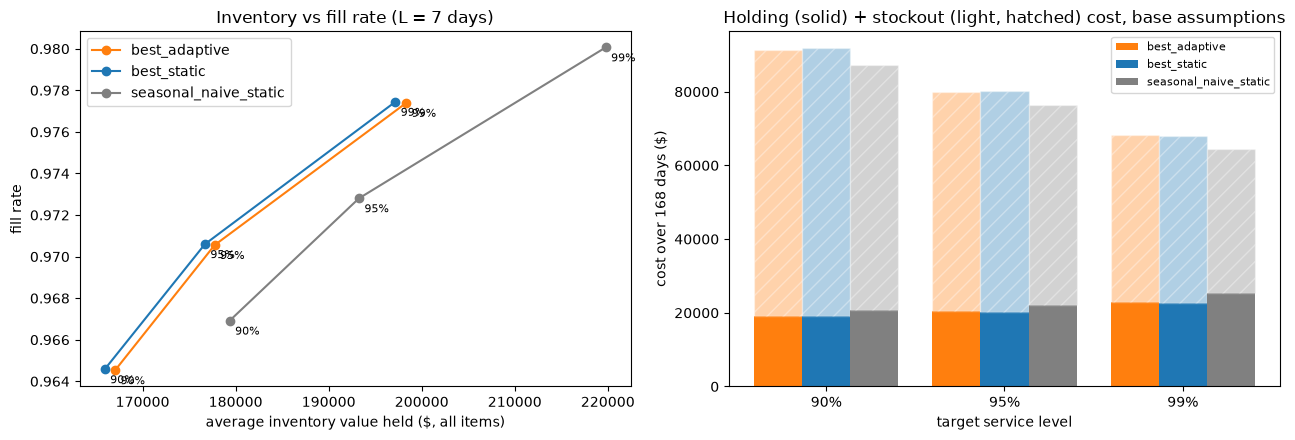

In [8]:
COLORS = {f'{MODEL}_static': 'tab:blue', f'{MODEL}_adaptive': 'tab:orange', 'seasonal_naive_static': 'grey'}
s = summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for policy, g in s.groupby('policy'):
    axes[0].plot(g['avg_inventory_value'], g['fill_rate'], marker='o', color=COLORS[policy], label=policy)
    for _, r in g.iterrows():
        axes[0].annotate(f"{r['service_level']:.0%}", (r['avg_inventory_value'], r['fill_rate']), fontsize=8,
                         xytext=(4, -10), textcoords='offset points')
axes[0].set(xlabel='average inventory value held ($, all items)', ylabel='fill rate',
            title=f'Inventory vs fill rate (L = {BASE_L} days)')
axes[0].legend()
x = np.arange(len(SERVICE_LEVELS))
for i, (policy, g) in enumerate(s.groupby('policy')):
    axes[1].bar(x + i * 0.27, g['holding_cost'], 0.27, color=COLORS[policy], label=policy)
    axes[1].bar(x + i * 0.27, g['stockout_cost'], 0.27, bottom=g['holding_cost'], color=COLORS[policy],
                alpha=0.35, hatch='//', edgecolor='white')
axes[1].set_xticks(x + 0.27, [f"{sl:.0%}" for sl in SERVICE_LEVELS])
axes[1].set(xlabel='target service level', ylabel='cost over 168 days ($)',
            title='Holding (solid) + stockout (light, hatched) cost, base assumptions')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../outputs/figures/inventory_tradeoff.png", dpi=120)
plt.show()

## What we found

With the textbook safety stock the better forecast does not save money. At a 95% target and a 7-day lead time, the
static combination holds $176,693 of stock on average against $193,251 for seasonal naive (8.6% less), but it runs
out more often (3,547 stockout days against 3,026, fill rate 97.1% against 97.3%), and the lost sales cost more than
the stock it saves: $80,250 in total against $76,429, 5.0% more. It is dearer in every category at 95% (FOODS $55,133
against $52,539, HOBBIES $3,922 against $3,547, HOUSEHOLD $21,195 against $20,343). The textbook formula sizes safety
stock from the spread of past errors; the combination's smaller errors give it a smaller safety stock (29.9 units per
product against 37.3), and that turns out to be too small. 11c sizes safety stock from the errors themselves.

This holds across the cost assumptions: over all 108 scenarios the static combination is on average 6.2% more
expensive than seasonal naive, cheaper in only 7 of them, from 2.5% cheaper to 14.6% dearer.

Retraining after shifts makes no useful difference. At a 7-day lead time it costs 0.5% less in total at 95% (p =
0.83). At a 3-day lead time it costs 0.8-2.2% more (significantly at 95%), at 14 days 2.6-3.6% less (not
significantly), and over the 108 scenarios it is on average 0.5% cheaper, between 2.9% cheaper and 1.9% dearer.

The highest target, 99%, was the cheapest of the three in every scenario: holding one more unit for a week costs
about 0.5% of its price, while a lost sale costs 25-200% of it, so extra safety stock pays for itself. And the
textbook safety stock under-delivers: 11c measures how much.

With SARIMA, static held 8.4% less stock than seasonal naive at 2.6% lower cost. With LightGBM, in the earlier
version of the project, it was 16.6% less stock at 10.1% lower cost, partly because LightGBM forecast 3.6% low, which
also cut stock.

## What comes next

`11c_calibrated_safety_stock` replaces the textbook safety stock with one sized from the errors.

In [9]:
# files this notebook wrote
from pathlib import Path
ROOT = Path('..').resolve()
written = [ROOT / p for p in ['data/processed/inventory_item_kpis.csv', 'data/processed/inventory_daily.parquet', 'outputs/tables/inventory_policy_summary.csv', 'outputs/tables/inventory_policy_summary_by_category.csv', 'outputs/tables/inventory_adaptive_vs_static_tests.csv', 'outputs/tables/inventory_cost_sensitivity.csv', 'outputs/figures/inventory_tradeoff.png']]
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\inventory_item_kpis.csv 5,260 KB
data\processed\inventory_daily.parquet 9,894 KB
outputs\tables\inventory_policy_summary.csv 1 KB
outputs\tables\inventory_policy_summary_by_category.csv 2 KB
outputs\tables\inventory_adaptive_vs_static_tests.csv 2 KB
outputs\tables\inventory_cost_sensitivity.csv 17 KB
outputs\figures\inventory_tradeoff.png 95 KB
